# Part 1: Trace and test the learning mechanism
 
 - x = [1.0, 2.0]                         y = 1

 - W1 = [[ 0.5, 0.25],                    b1 = [0.0, -0.5]
      [-0.5, 1.00]]

 - h = ReLU(W1 x + b1)

 - W2 = [0.8, -0.4]                       b2 = 0.1

 - logit = W2 h + b2

 - loss = binary cross-entropy with logits

### Calculate and show the hidden pre-activations, hidden activations, output logit, sigmoid probability, and loss.

(mathematical workings calculated on paper)

 hidden-pre : [1.0,1.0],
 hidden: [1.0,1.0],
 logit = 0.5,
 prob = 0.6225,
 loss = 0.4741

### Use the chain rule to calculate the gradient of the loss with respect to W2, b2, W1, and b1.

(mathematical workings on paper)

 dL/dlogit = p - y = 0.6225 - 1 = -0.3775

 dL/dW2 = (-0.3775,-0.3775)

 dL/db2 = -0.3775

 dL/db1 = (-0.302, 0.151)
 
 dL/dz = (-0.302, 0.151)

 dL/dW1 = [(-0.302,-0.604),(0.151,0.302)]

### Apply one gradient-descent update with learning rate 0.1 and confirm that the loss decreases.

new W2 = (0.83775, -0.36225), new b2 = 0.13775








In [2]:
import torch
import torch.nn.functional as F

x = torch.tensor([1.0, 2.0])
y = torch.tensor(1.0)

W1 = torch.tensor([
    [0.5, 0.25],
    [-0.5, 1.0]
], requires_grad=True)

b1 = torch.tensor([0.0, -0.5], requires_grad=True)

W2 = torch.tensor([0.8, -0.4], requires_grad=True)
b2 = torch.tensor(0.1, requires_grad=True)

z = W1 @ x + b1
h = torch.relu(z)
logit = W2 @ h + b2

loss = F.binary_cross_entropy_with_logits(logit, y)

loss.backward()

print("z =", z)
print("h =", h)
print("logit =", logit)
print("probability =", torch.sigmoid(logit))
print("loss =", loss)

print("\ndL/dW2 =", W2.grad)
print("dL/db2 =", b2.grad)
print("dL/dW1 =")
print(W1.grad)
print("dL/db1 =", b1.grad)

z = tensor([1., 1.], grad_fn=<AddBackward0>)
h = tensor([1., 1.], grad_fn=<ReluBackward0>)
logit = tensor(0.5000, grad_fn=<AddBackward0>)
probability = tensor(0.6225, grad_fn=<SigmoidBackward0>)
loss = tensor(0.4741, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)

dL/dW2 = tensor([-0.3775, -0.3775])
dL/db2 = tensor(-0.3775)
dL/dW1 =
tensor([[-0.3020, -0.6041],
        [ 0.1510,  0.3020]])
dL/db1 = tensor([-0.3020,  0.1510])


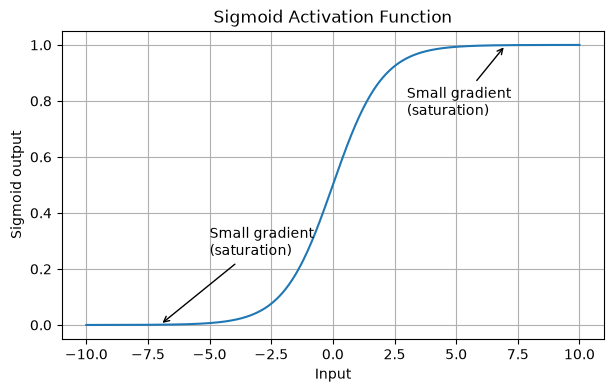

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 500)

sigmoid = 1 / (1 + np.exp(-x))
relu = np.maximum(0, x)


plt.figure(figsize=(7, 4))

plt.plot(x, sigmoid)
plt.xlabel("Input")
plt.ylabel("Sigmoid output")
plt.title("Sigmoid Activation Function")
plt.grid()


plt.annotate(
    "Small gradient\n(saturation)",
    xy=(7, 0.999),
    xytext=(3, 0.75),
    arrowprops=dict(arrowstyle="->")
)

plt.annotate(
    "Small gradient\n(saturation)",
    xy=(-7, 0.001),
    xytext=(-5, 0.25),
    arrowprops=dict(arrowstyle="->")
)

plt.show()

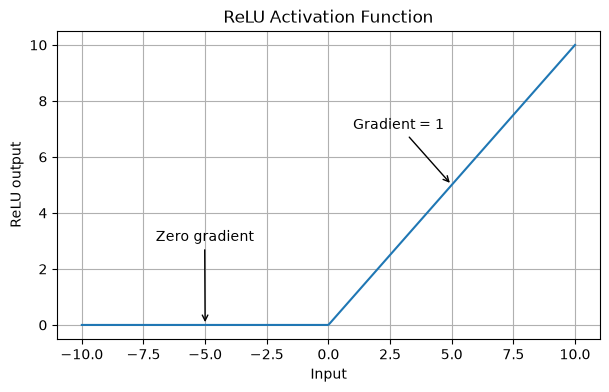

In [4]:
plt.figure(figsize=(7, 4))

plt.plot(x, relu)
plt.xlabel("Input")
plt.ylabel("ReLU output")
plt.title("ReLU Activation Function")
plt.grid()

plt.annotate(
    "Zero gradient",
    xy=(-5, 0),
    xytext=(-7, 3),
    arrowprops=dict(arrowstyle="->")
)

plt.annotate(
    "Gradient = 1",
    xy=(5, 5),
    xytext=(1, 7),
    arrowprops=dict(arrowstyle="->")
)

plt.show()

Sigmoid saturation: For very large positive or negative inputs, the sigmoid function becomes nearly flat, so its gradient approaches zero. During backpropagation, these small gradients can reduce the gradient reaching earlier layers and contribute to the vanishing-gradient problem.
ReLU advantage: For positive inputs, ReLU has a gradient of 1, allowing gradients to pass backward without shrinking due to the activation function.
ReLU risk: For negative inputs, ReLU has a gradient of zero. A neuron that remains in this region may stop receiving useful gradient updates, producing a “dead ReLU.”

In [5]:
# Regression check

outputs = torch.tensor([
    [2.5],
    [1.2],
    [3.1]
])
targets = torch.tensor([
    [2.7],
    [1.1],
    [3.0]
])   

loss_function = torch.nn.MSELoss()
loss = loss_function(outputs, targets)

predictions = outputs

print("Output shape:", outputs.shape)
print("Target shape:", targets.shape)
print("Target dtype:", targets.dtype)
print("Loss:", loss.item())
print("Predictions:")
print(predictions)  

Output shape: torch.Size([3, 1])
Target shape: torch.Size([3, 1])
Target dtype: torch.float32
Loss: 0.020000001415610313
Predictions:
tensor([[2.5000],
        [1.2000],
        [3.1000]])


In [6]:
# Classification check

outputs = torch.tensor([
    [2.5],
    [-1.2],
    [3.1]
])

targets = torch.tensor([
    [1],
    [0],
    [1]
])

loss_function = torch.nn.BCEWithLogitsLoss()
loss = loss_function(outputs, targets.float())

probabilities = torch.sigmoid(outputs)
predictions = (probabilities >= 0.5).int()

print("Output shape:", outputs.shape)
print("Target shape:", targets.shape)
print("Target dtype:", targets.dtype)
print("Loss:", loss.item())
print("Probabilities:", probabilities)
print("Predictions:", predictions)


Output shape: torch.Size([3, 1])
Target shape: torch.Size([3, 1])
Target dtype: torch.int64
Loss: 0.12874537706375122
Probabilities: tensor([[0.9241],
        [0.2315],
        [0.9569]])
Predictions: tensor([[1],
        [0],
        [1]], dtype=torch.int32)


In [7]:
# Multiclass classification check

outputs = torch.tensor([
    [2.0, 1.0, 0.1],
    [0.2, 0.5, 1.8],
    [0.1, 2.1, 0.3]
])

targets = torch.tensor([0, 2, 1], dtype=torch.long)

loss_function = torch.nn.CrossEntropyLoss()
loss = loss_function(outputs, targets)

probabilities = torch.softmax(outputs, dim=1)
predictions = torch.argmax(probabilities, dim=1)

print("Output shape:", outputs.shape)
print("Target shape:", targets.shape)
print("Target dtype:", targets.dtype)
print("Loss:", loss.item())
print("Probabilities:")
print(probabilities)
print("Probability row sums:", probabilities.sum(dim=1))
print("Predictions:", predictions)

Output shape: torch.Size([3, 3])
Target shape: torch.Size([3])
Target dtype: torch.int64
Loss: 0.3560508191585541
Probabilities:
tensor([[0.6590, 0.2424, 0.0986],
        [0.1369, 0.1848, 0.6782],
        [0.1041, 0.7689, 0.1271]])
Probability row sums: tensor([1.0000, 1.0000, 1.0000])
Predictions: tensor([0, 2, 1])


####  Explain how a one-hot target differs from a class-index target and when independent sigmoids describe multi-label rather than multiclass classification.

A class-index target represents the correct class using a single integer, while a one-hot target represents it as a vector containing 1 for the correct class and 0 for all other classes.

Independent sigmoids are used for multi-label classification when multiple labels can be true for the same sample, whereas multiclass classification assumes exactly one class is correct and therefore uses competing class probabilities, typically produced with softmax.




# Part 2: Prepare the real experiment

In [8]:
#  - - - - - - - - Import libraries - - - - - - - - - - - 
# General
import random
import time

# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt

# Data preparation and analysis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# PyTorch
import torch
import torch.nn.functional as F



repo_root='/Users/evanlin/2026-summar-ai/'
file_path = repo_root + 'sections/s02/homework/openpoly_calculated_properties.csv'
df = pd.read_csv(file_path)

seed = 42
random.seed(seed)
np.random.seed(seed)

#  - - - - - - - - - - Data cleaning and splitting - - - - -- - - - - - - 

cleaned_df = df[df['Energy_Hatree'] != 0].drop(columns=['id','Name', 'reactant_1', 'reactant_2', 'psmiles', 'SMILES', 'reaction_type', 'Software', 'Theory_Level', 'Source', 'HOMO_eV', 'LUMO_eV'])

indices = cleaned_df.index

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=seed
)

nn_train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.2,
    random_state=seed  
)

#  - - - -- - - - -- -- -- --   General data dfs - -- - -- -- ---- - - - -- - -

nn_train_df = cleaned_df.loc[nn_train_idx]
test_df = cleaned_df.loc[test_idx]
val_df = cleaned_df.loc[val_idx]

#Predictors data dfs

nn_train_df_predictors = nn_train_df.drop(columns=['HOMO_LUMO_Gap_eV'])
test_df_predictors = test_df.drop(columns=['HOMO_LUMO_Gap_eV'])
val_df_predictors = val_df.drop(columns=['HOMO_LUMO_Gap_eV'])

# - - - - - --- - -- - - - - - - Target data dfs - - - - - - - - - - - - - - - - - 

nn_train_df_target = nn_train_df[['HOMO_LUMO_Gap_eV']]
test_df_target = test_df[['HOMO_LUMO_Gap_eV']]
val_df_target = val_df[['HOMO_LUMO_Gap_eV']]

# - - - - - - - - - - - - - - - - Data reporting - - - - - - - - - - - - - - - - - 

print("Training set size:", len(nn_train_df))
print("Validation set size:", len(val_df))
print("Test set size:", len(test_df))
print("Training/validation overlap:", len(set(nn_train_df.index).intersection(set(val_df.index))))
print("Training/test overlap:", len(set(nn_train_df.index).intersection(set(test_df.index))))
print("Validation/test overlap:", len(set(val_df.index).intersection(set(test_df.index))))



Training set size: 592
Validation set size: 148
Test set size: 186
Training/validation overlap: 0
Training/test overlap: 0
Validation/test overlap: 0


----------------------Update data distributions-----------------------
Training:
       HOMO_LUMO_Gap_eV
count        592.000000
mean           8.304032
std            0.465384
min            6.512300
25%            8.015425
50%            8.315150
75%            8.593650
max            9.875600

Validation:
       HOMO_LUMO_Gap_eV
count        148.000000
mean           8.320255
std            0.492680
min            6.878400
25%            7.990375
50%            8.346950
75%            8.593850
max           10.001000

Test:
       HOMO_LUMO_Gap_eV
count        186.000000
mean           8.311601
std            0.523014
min            4.468900
25%            8.088800
50%            8.364100
75%            8.638600
max            9.694100
----------------------Update data histograms-----------------------


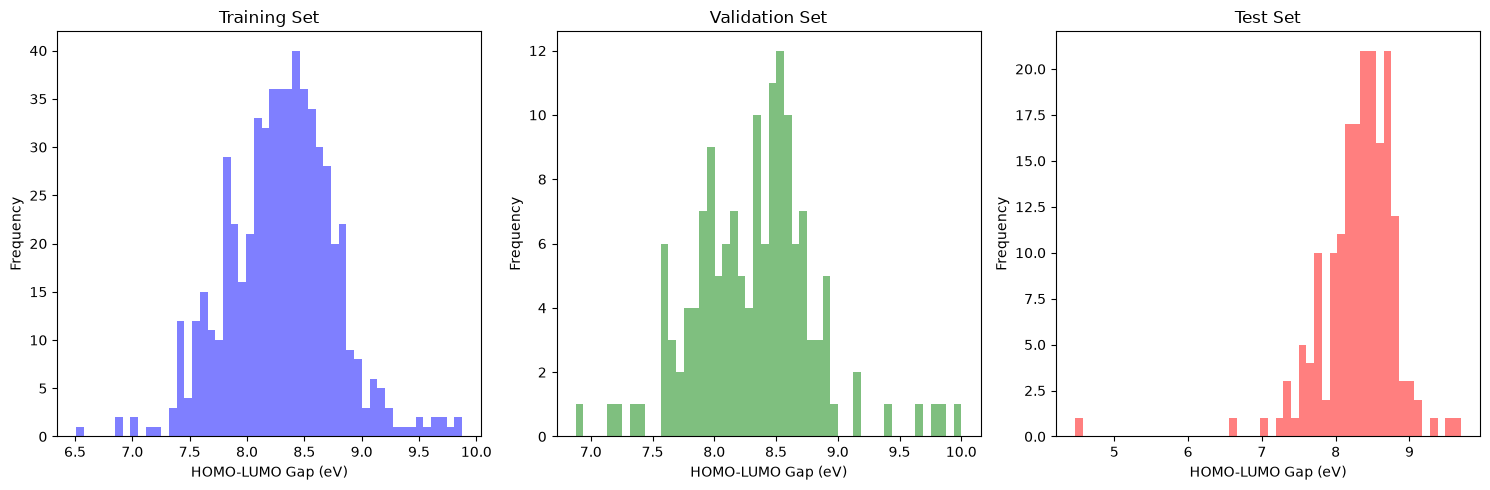

----------------------Corresponding box plots-----------------------


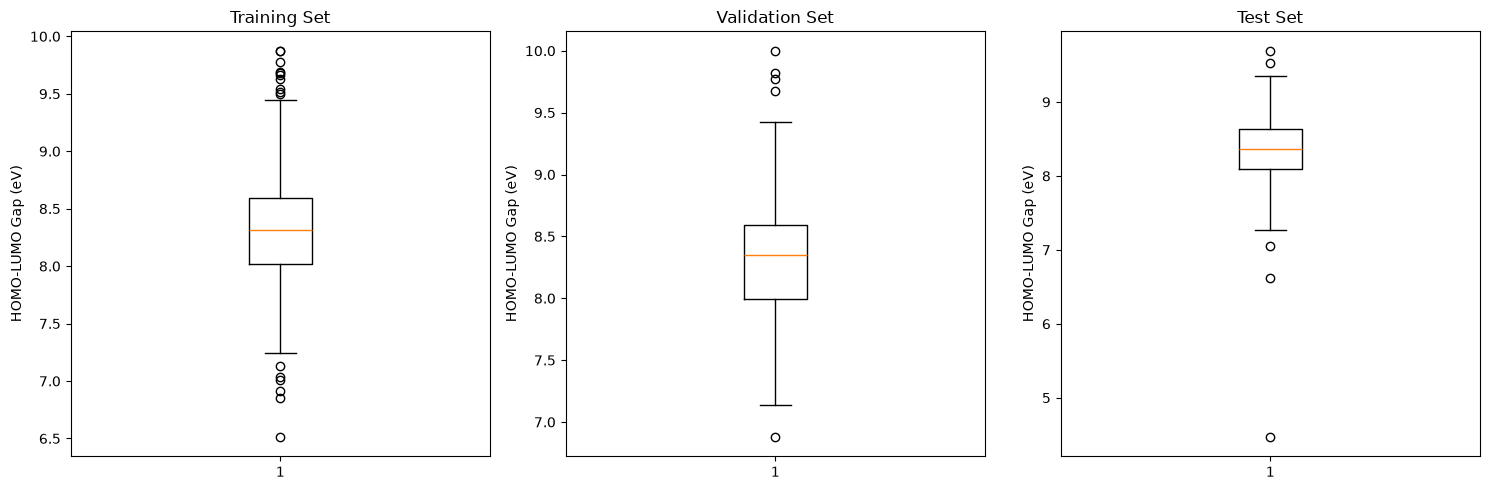

In [9]:
#  - - - - - - - - - - - - - - - - - - target distributions and histograms  -- - - - - - - - - - 

print("----------------------Update data distributions-----------------------")
print("Training:")
print(nn_train_df_target.describe())

print("\nValidation:")
print(val_df_target.describe())

print("\nTest:")
print(test_df_target.describe())


print("----------------------Update data histograms-----------------------")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(nn_train_df_target, bins=50, color='blue', alpha=0.5)
plt.title('Training Set')
plt.xlabel('HOMO-LUMO Gap (eV)')
plt.ylabel('Frequency')

plt.subplot(1, 3, 2)
plt.hist(val_df_target, bins=50, color='green', alpha=0.5)
plt.title('Validation Set')
plt.xlabel('HOMO-LUMO Gap (eV)')
plt.ylabel('Frequency')

plt.subplot(1, 3, 3)
plt.hist(test_df_target, bins=50, color='red', alpha=0.5)
plt.title('Test Set')
plt.xlabel('HOMO-LUMO Gap (eV)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

print("----------------------Corresponding box plots-----------------------")
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.boxplot(nn_train_df_target['HOMO_LUMO_Gap_eV'])
plt.title('Training Set')
plt.ylabel('HOMO-LUMO Gap (eV)')

plt.subplot(1, 3, 2)
plt.boxplot(val_df_target['HOMO_LUMO_Gap_eV'])
plt.title('Validation Set')
plt.ylabel('HOMO-LUMO Gap (eV)')

plt.subplot(1, 3, 3)
plt.boxplot(test_df_target['HOMO_LUMO_Gap_eV'])
plt.title('Test Set')
plt.ylabel('HOMO-LUMO Gap (eV)')

plt.tight_layout()
plt.show()


------------------------------------Correlation map------------------------------------


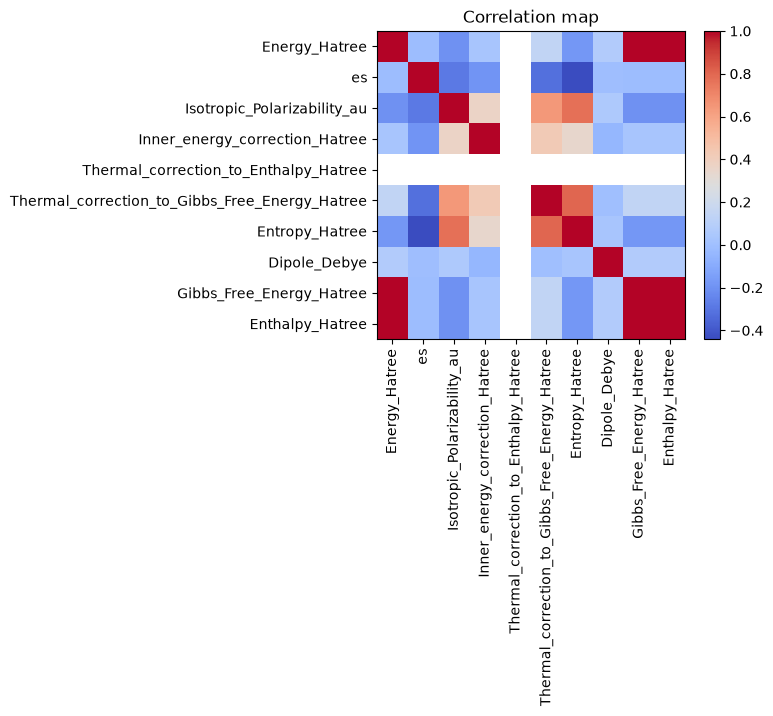

------------------------------------PCA Analysis------------------------------------
Explained variance ratio: 
 [3.57466788e-01 3.13067809e-01 1.12976475e-01 9.21205153e-02
 7.79365616e-02 3.32797479e-02 1.31521031e-02 1.01934410e-16
 2.73275230e-17 0.00000000e+00]
Cumulative variance: 
 [0.35746679 0.6705346  0.78351107 0.87563159 0.95356815 0.9868479
 1.         1.         1.         1.        ]


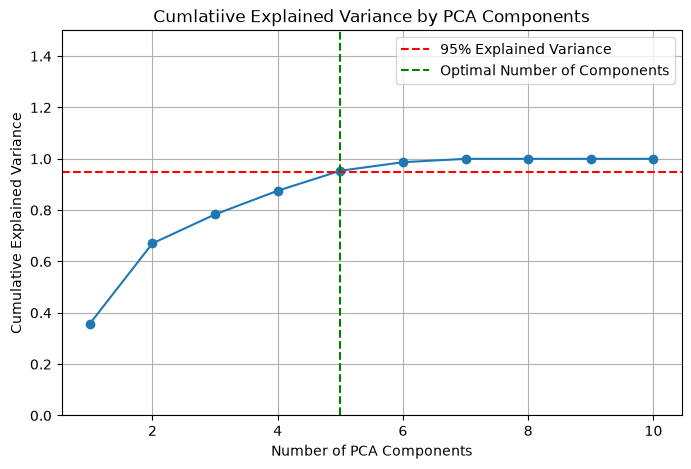

In [10]:
# ------------ - - - - - -  -- - - - - - - prepration for MLP inputs - - - - - - - - - - - - 
correlation_matrix = nn_train_df_predictors.corr()

print("------------------------------------Correlation map------------------------------------")
plt.figure(figsize=(5, 4))
plt.imshow(correlation_matrix, cmap='coolwarm')

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.colorbar()
plt.title("Correlation map")
plt.show()

print("------------------------------------PCA Analysis------------------------------------")

scaler = StandardScaler()
nn_train_df_predictors_scaled = scaler.fit_transform(nn_train_df_predictors)
test_df_predictors_scaled = scaler.transform(test_df_predictors)
val_df_predictors_scaled = scaler.transform(val_df_predictors)

pca = PCA()
nn_train_df_predictors_pca = pca.fit(nn_train_df_predictors_scaled)

print("Explained variance ratio: \n", pca.explained_variance_ratio_)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

print("Cumulative variance: \n", cumulative_variance)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.title('Cumlatiive Explained Variance by PCA Components')
plt.xlabel('Number of PCA Components')
plt.ylabel('Cumulative Explained Variance')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Explained Variance')
plt.axvline(x=np.argmax(cumulative_variance >= 0.95) + 1, color='g', linestyle='--', label='Optimal Number of Components')
plt.ylim(0,1.5)
plt.legend()
plt.grid()
plt.show()


In [11]:
print("Energy_Hatree == 0:", (nn_train_df["Energy_Hatree"] == 0).sum())
print("Energy_Hatree == 0:", (val_df["Energy_Hatree"] == 0).sum())
print("Energy_Hatree == 0:", (test_df["Energy_Hatree"] == 0).sum())

Energy_Hatree == 0: 0
Energy_Hatree == 0: 0
Energy_Hatree == 0: 0


### Reason for each decision in terms of cleaning the data

Data-quality and leakage decisions: No missing numerical values were identified. Rows with Energy_Hatree == 0 were treated as suspicious and removed before splitting. HOMO_eV and LUMO_eV were excluded from the MLP inputs because the regression target HOMO_LUMO_Gap_eV is directly calculated as LUMO_eV - HOMO_eV, which would introduce target leakage. The id column was retained only for identifying rows and verifying split independence, but excluded from the model inputs because it is not a meaningful predictive feature.

In [12]:
print("-----------------------Fit data and verifying the shape-----------------------")
print("Og Training set shape:", nn_train_df_predictors.shape)
print("Training set shape:", nn_train_df_predictors_scaled.shape)
print("Og Test set shape:", test_df_predictors.shape)
print("Test set shape:", test_df_predictors_scaled.shape)
print("Og Validation set shape:", val_df_predictors.shape)
print("Og Validation set shape:", val_df_predictors_scaled.shape)

-----------------------Fit data and verifying the shape-----------------------
Og Training set shape: (592, 10)
Training set shape: (592, 10)
Og Test set shape: (186, 10)
Test set shape: (186, 10)
Og Validation set shape: (148, 10)
Og Validation set shape: (148, 10)


-----------------------CNN's psmiles-----------------------
Table of sequence lengths:
         Training  Validation        Test
count  592.000000  148.000000  186.000000
mean    53.444257   54.547297   52.806452
std      9.125387    8.419555    9.811475
min     35.000000   37.000000   38.000000
25%     47.000000   48.000000   47.000000
50%     52.000000   54.000000   50.000000
75%     58.000000   60.000000   56.000000
max     98.000000   81.000000   97.000000


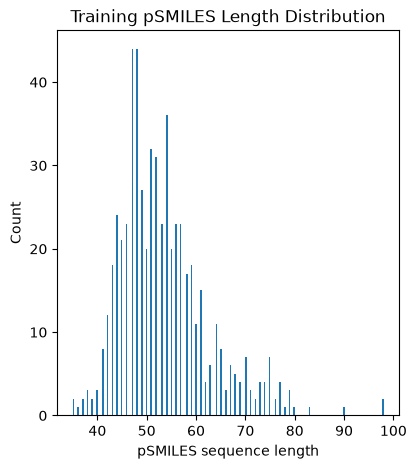

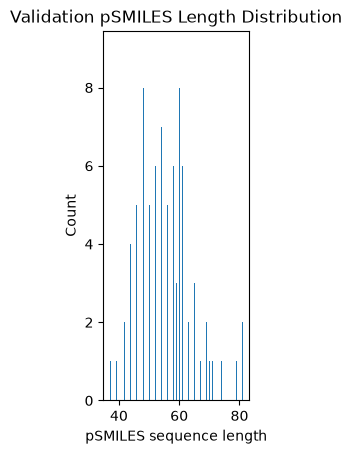

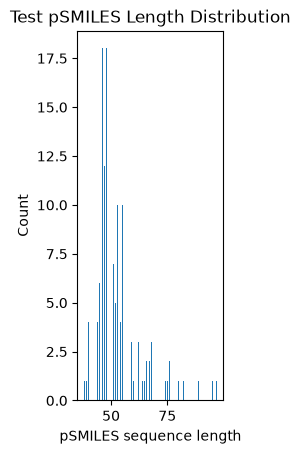

Character counts in training pSMILES sequences:
Counter({'c': 6688, '(': 4460, ')': 4460, 'C': 4184, 'O': 2995, '=': 2237, 'N': 1557, '1': 1530, '*': 1184, '2': 760, 'F': 299, 'S': 230, 'n': 218, '3': 164, 'B': 155, 'r': 155, 'l': 145, '#': 44, '4': 38, '-': 34, 's': 19, '[': 18, 'H': 18, ']': 18, 'o': 17, '5': 4, '6': 4, '7': 4})


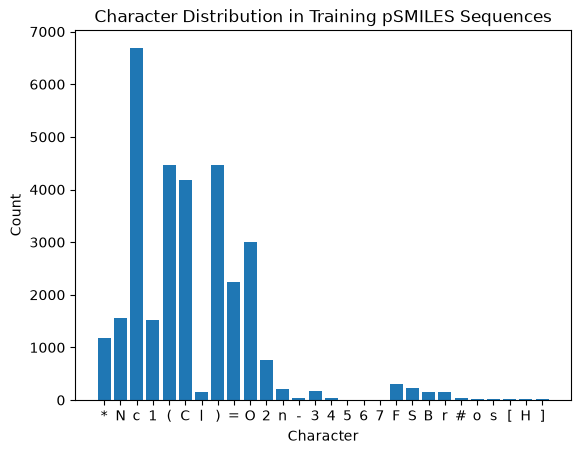

Vocabulary size:
30
------------------------Number of unknown characters in pSMILES sequences-----------------------
Number of unknown characters in training set:
0
Number of unknown characters in validation set:
0
Number of unknown characters in test set:
1
------------------------Max length of pSMILES sequences-----------------------
Max length of pSMILES sequences in training set:
98
Max length of pSMILES sequences in validation set:
81
Max length of pSMILES sequences in test set:
97
------------------------Padding rate of pSMILES sequences-----------------------
Padding rate of pSMILES sequences in training set:
0.45465044125758414
Padding rate of pSMILES sequences in validation set:
0.4433949255377827
Padding rate of pSMILES sequences in test set:
0.4611586570111916
------------------------Truncation rate of pSMILES sequences-----------------------
Truncation rate of pSMILES sequences in training set:
0.0
Truncation rate of pSMILES sequences in validation set:
0.0
Truncation rate 

In [13]:
print("-----------------------CNN's psmiles-----------------------")
# the length of the psmiles sequences in the training, validation, and test sets
cnn_nn_train = df.loc[nn_train_idx, "psmiles"]
cnn_test = df.loc[test_idx, "psmiles"]
cnn_val = df.loc[val_idx, "psmiles"]

cnn_nn_train_length = cnn_nn_train.str.len()
cnn_test_length = cnn_test.str.len()
cnn_val_length = cnn_val.str.len()

table_sequence_lengths = pd.DataFrame({

    "Training": cnn_nn_train_length.describe(),
    "Validation": cnn_val_length.describe(),
    "Test": cnn_test_length.describe()
})

print("Table of sequence lengths:")
print(table_sequence_lengths)

plt.figure(figsize=(15, 5))

plt.subplot (1, 3, 1)
plt.hist(cnn_nn_train_length, bins=200)
plt.xlabel("pSMILES sequence length")
plt.ylabel("Count")
plt.title("Training pSMILES Length Distribution")
plt.show()

plt.subplot (1, 3, 2)
plt.hist(cnn_val_length, bins=200)
plt.xlabel("pSMILES sequence length")
plt.ylabel("Count")
plt.title("Validation pSMILES Length Distribution")
plt.show()

plt.subplot (1, 3, 3)
plt.hist(cnn_test_length, bins=200)
plt.xlabel("pSMILES sequence length")
plt.ylabel("Count")
plt.title("Test pSMILES Length Distribution")
plt.show()


# the distribution of characters in the psmiles sequences in the training set
from collections import Counter

character_counts = Counter(
    character
    for sequence in cnn_nn_train
    for character in sequence
)

print("Character counts in training pSMILES sequences:")
print(character_counts)

characters = list(character_counts.keys())
counts = list(character_counts.values())

plt.bar(characters, counts)
plt.xlabel("Character")
plt.ylabel("Count")
plt.title("Character Distribution in Training pSMILES Sequences")
plt.show()

# vocab sizing, turning letters into numbers, and padding sequences
vocab = {
    "<PAD>": 0,
    "<UNK>": 1,
}

for character in character_counts.keys():
    if character not in vocab:
        vocab[character] = len(vocab)

print("Vocabulary size:")
print(len(vocab))

# number of unknown characters 
def num_unknown_characters(sequences, vocab):
    count = 0

    for sequence in sequences:
        for character in sequence:
            if character not in vocab:
                count += 1
    return count

unknown_count_train = num_unknown_characters(cnn_nn_train, vocab)
unknown_count_val = num_unknown_characters(cnn_val, vocab)
unknown_count_test = num_unknown_characters(cnn_test, vocab)

print("------------------------Number of unknown characters in pSMILES sequences-----------------------")
print("Number of unknown characters in training set:")
print(unknown_count_train)

print("Number of unknown characters in validation set:")
print(unknown_count_val)

print("Number of unknown characters in test set:")
print(unknown_count_test)   

# max length of psmiles sequences
print("------------------------Max length of pSMILES sequences-----------------------")
print("Max length of pSMILES sequences in training set:")
print(cnn_nn_train_length.max())
print("Max length of pSMILES sequences in validation set:")
print(cnn_val_length.max())
print("Max length of pSMILES sequences in test set:")
print(cnn_test_length.max())

# padding rate of psmiles sequences
print("------------------------Padding rate of pSMILES sequences-----------------------")
max_length = cnn_nn_train_length.max()
def padding_rate(sequence_lengths, max_length):
    total_counts = len(sequence_lengths) * max_length
    padding_counts = sum(max_length - length for length in sequence_lengths if length < max_length)
    return padding_counts / total_counts


print("Padding rate of pSMILES sequences in training set:")
print(padding_rate(cnn_nn_train_length, max_length))

print("Padding rate of pSMILES sequences in validation set:")
print(padding_rate(cnn_val_length, max_length))

print("Padding rate of pSMILES sequences in test set:")
print(padding_rate(cnn_test_length, max_length))


# Truncation rate of psmiles sequences
print("------------------------Truncation rate of pSMILES sequences-----------------------")
max_length = cnn_nn_train_length.max()
def truncation_rate(sequence_lengths, max_length):
    total_counts = len(sequence_lengths) * max_length
    truncation_counts = sum(length - max_length for length in sequence_lengths if length > max_length)
    return truncation_counts / total_counts


print("Truncation rate of pSMILES sequences in training set:")
print(truncation_rate(cnn_nn_train_length, max_length))

print("Truncation rate of pSMILES sequences in validation set:")
print(truncation_rate(cnn_val_length, max_length))

print("Truncation rate of pSMILES sequences in test set:")
print(truncation_rate(cnn_test_length, max_length))

print("Why the CNN input has local order while the MLP's tabular columns do not?")
print("The CNN input has local order because pSMILES is a sequence in which neighbouring characters and their arrangement carry structural information, whereas the MLP receives separate tabular features whose physical column order does not represent a meaningful sequence or neighbourhood.")

# Part 3: Train and tune an MLP


Number of MLP inputs: 10
MLP(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Number of parameters in the model: 385
Learning rate: 0.001
Weighted decay: 0
Optimizer: Adam
Batch size: 32
Max epochs: 500
Patience: 20
-----------------modelings data shape---------------------
Train predictors: torch.Size([592, 10])
Train targets: torch.Size([592, 1])
Validation predictors: torch.Size([148, 10])
Validation targets: torch.Size([148, 1])
Test predictors: torch.Size([186, 10])
Test targets: torch.Size([186, 1])
Batch predictors: torch.Size([32, 10])
Batch targets: torch.Size([32, 1])
-------------------------------------plots of epoches


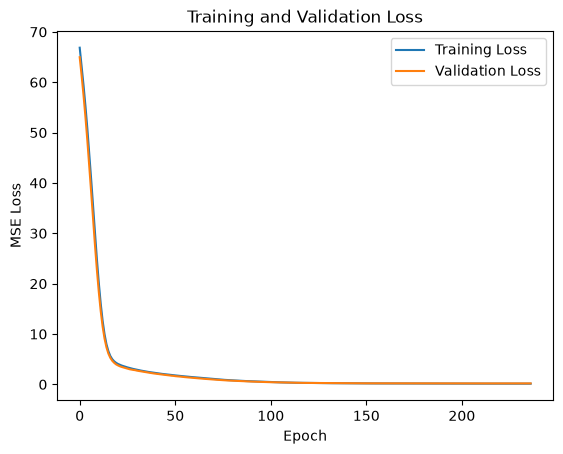

In [14]:
# Determining the number of inputs for the MLP model based on the number of features in the scaled training predictors
input_size = nn_train_df_predictors_scaled.shape[1]

print("Number of MLP inputs:", input_size)

# MLP model definition

import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)


model = MLP(input_size)
torch.manual_seed(42)
print(model)

# parameters of the model
parameter_count = sum(p.numel() for p in model.parameters())
print("Number of parameters in the model:", parameter_count)

# loss function, optimizer and learning rate
loss_function = nn.MSELoss()

learning_rate = 0.001
print("Learning rate:", learning_rate)

weighted_decay=0
print("Weighted decay:", weighted_decay)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr = learning_rate,
    weight_decay = weighted_decay
)
print("Optimizer: Adam")

# batches 
batch_size = 32
print("Batch size:", batch_size)

# max epoch 
max_epochs = 500
print("Max epochs:", max_epochs)

# stopping rule
patience = 20
print("Patience:", patience)

# Now the modelling starts converting data in pytorch usables
# predictors

train_predictors_tensors = torch.tensor(
    nn_train_df_predictors_scaled,
    dtype=torch.float32
)

val_predictors_tensors = torch.tensor(
    val_df_predictors_scaled,
    dtype=torch.float32
)

test_predictors_tensors = torch.tensor(
    test_df_predictors_scaled,
    dtype=torch.float32
)

# targets
train_target_tensor = torch.tensor(
    nn_train_df_target.to_numpy(),
    dtype=torch.float32
).view(-1, 1)

val_target_tensor = torch.tensor(
    val_df_target.to_numpy(),
    dtype=torch.float32
).view(-1, 1)

test_target_tensor = torch.tensor(
    test_df_target.to_numpy(),
    dtype=torch.float32
).view(-1,1)

print("-----------------modelings data shape---------------------")
print("Train predictors:", train_predictors_tensors.shape)
print("Train targets:", train_target_tensor.shape)
print("Validation predictors:", val_predictors_tensors.shape)
print("Validation targets:", val_target_tensor.shape)
print("Test predictors:", test_predictors_tensors.shape)
print("Test targets:", test_target_tensor.shape)

# batch making 
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(
    train_predictors_tensors,
    train_target_tensor
)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)
for predictor_batch, target_batch in train_loader:
    print("Batch predictors:", predictor_batch.shape)
    print("Batch targets:", target_batch.shape)
    break

#the model
# stopping at the lowest validation loss

import copy

best_val_loss = float("inf")
best_model_state = None
best_epoch = 0
epochs_without_improvement = 0



train_losses = []
val_losses = []

for epoch in range(max_epochs):

    model.train()
    
    total_train_losses = 0

    for predictor_batch, target_batch in train_loader:

        optimizer.zero_grad()
        predictions = model(predictor_batch)
        loss = loss_function(predictions, target_batch)
        loss.backward()
        optimizer.step()

        total_train_losses += loss.item() * predictor_batch.size(0)

    average_train_losses = total_train_losses / len(train_dataset)
    train_losses.append(average_train_losses)

    model.eval()


    with torch.no_grad():
        validation_predictions = model(val_predictors_tensors)
        validation_loss = loss_function(
            validation_predictions,
            val_target_tensor
        )

    val_losses.append(validation_loss.item())

    if validation_loss.item() < best_val_loss:
        best_val_loss = validation_loss.item()
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        break

print("-------------------------------------plots of epoches")

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()   



In [15]:
print("First training loss:", train_losses[0])
print("First validation loss:", val_losses[0])

print("Final training loss:", train_losses[-1])
print("Final validation loss:", val_losses[-1])

print("Best validation loss:", best_val_loss)
print("Best epoch:", best_epoch)

First training loss: 66.8622339609507
First validation loss: 64.97135162353516
Final training loss: 0.13636484862984838
Final validation loss: 0.1942085176706314
Best validation loss: 0.1908341944217682
Best epoch: 217


----------------------------------weight decays--------------------------------
Config A: weight decay = 0
Best validation loss: 0.19604311883449554
Best epoch: 202

Config B: weight decay = 0.0001
Best validation loss: 0.19615699350833893
Best epoch: 202
----------------------------------plots of weight decays--------------------------------


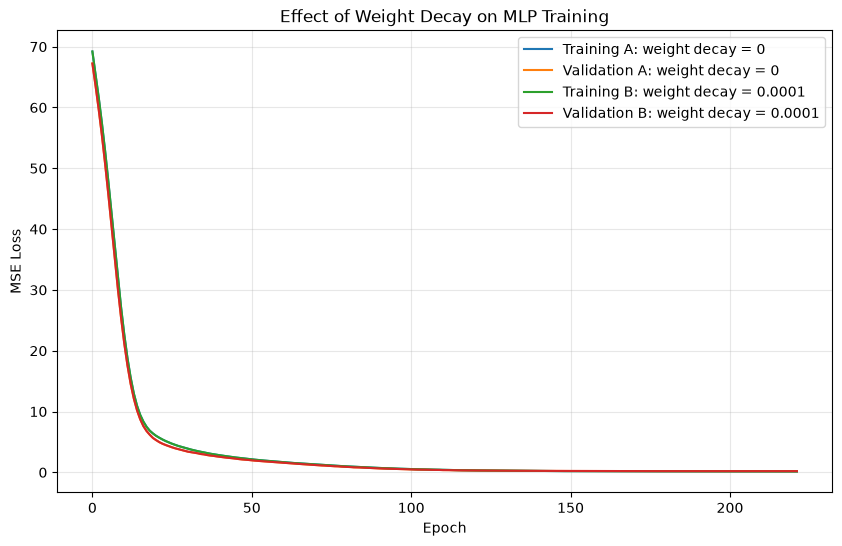

In [16]:
# Turning the whole model into function of weight_decay 

def train_model(weight_decay):

    torch.manual_seed(42)

    model = MLP(input_size)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_model_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(max_epochs):

        model.train()
        total_train_loss = 0

        for predictor_batch, target_batch in train_loader:

            optimizer.zero_grad()

            predictions = model(predictor_batch)
            loss = loss_function(predictions, target_batch)

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * predictor_batch.size(0)

        average_train_loss = total_train_loss / len(train_dataset)
        train_losses.append(average_train_loss)


        model.eval()

        with torch.no_grad():

            validation_predictions = model(val_predictors_tensors)

            validation_loss = loss_function(
                validation_predictions,
                val_target_tensor
            )

        val_losses.append(validation_loss.item())


        if validation_loss.item() < best_val_loss:

            best_val_loss = validation_loss.item()
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1


        if epochs_without_improvement >= patience:
            break


    model.load_state_dict(best_model_state)

    return model, train_losses, val_losses, best_val_loss, best_epoch

# Comparing the two weight decays


model_A, train_A, val_A, best_val_A, best_epoch_A = train_model(
    weight_decay=0.0
)

model_B, train_B, val_B, best_val_B, best_epoch_B = train_model(
    weight_decay=0.0001
)

print("----------------------------------weight decays--------------------------------")

print("Config A: weight decay = 0")
print("Best validation loss:", best_val_A)
print("Best epoch:", best_epoch_A)

print()

print("Config B: weight decay = 0.0001")
print("Best validation loss:", best_val_B)
print("Best epoch:", best_epoch_B)

print("----------------------------------plots of weight decays--------------------------------")

plt.figure(figsize=(10, 6))

plt.plot(train_A, label="Training A: weight decay = 0")
plt.plot(val_A, label="Validation A: weight decay = 0")

plt.plot(train_B, label="Training B: weight decay = 0.0001")
plt.plot(val_B, label="Validation B: weight decay = 0.0001")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Effect of Weight Decay on MLP Training")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


The training and validation losses decreased smoothly for both configurations, indicating stable optimization without large oscillations. The validation losses remained reasonably close to the training losses, although the lower training losses suggest a small generalization gap rather than severe overfitting.

The two configurations differed only in weight decay. Config A used no weight decay and achieved a best validation MSE of 0.196043 at epoch 202. Config B used a weight decay of 0.0001 and achieved a slightly higher validation MSE of 0.196157, also at epoch 202. Because lower MSE is better, Config A performed marginally better. However, the difference was only approximately 0.06%, so weight decay had no practically meaningful effect in this experiment.

The result did not support the prediction that a small amount of weight decay would improve validation performance. Both configurations produced almost identical results, suggesting that this level of regularization had little influence on the model. Config A was selected because it had the lowest validation loss.

# Part 4: Train a 1D CNN


In [17]:
# tokenisation
def tokenisation(sequence, vocab, max_length):
    token_ids = []

    for character in sequence:
        token_id = vocab.get(character, vocab["<UNK>"])
        token_ids.append(token_id)

    token_ids = token_ids[:max_length]

    padding_needed = max_length - len(token_ids)
    token_ids += [vocab["<PAD>"]] * padding_needed

    return token_ids

# the list of tokens

cnn_nn_train_tokens_ids = [
    tokenisation(sequence, vocab, max_length)
    for sequence in cnn_nn_train
]

cnn_val_tokens_ids = [
    tokenisation(sequence, vocab, max_length)
    for sequence in cnn_val
]

cnn_test_tokens_ids = [
    tokenisation(sequence, vocab, max_length)
    for sequence in cnn_test
]

print("Training sequences:", len(cnn_nn_train_tokens_ids))
print("Validation sequences:", len(cnn_val_tokens_ids))
print("Test sequences:", len(cnn_test_tokens_ids))

print("Length of one encoded sequence:", len(cnn_nn_train_tokens_ids[0]))

# converstion into tensors

cnn_train_token_tensors = torch.tensor(
    cnn_nn_train_tokens_ids,
    dtype=torch.long
)

cnn_val_token_tensors = torch.tensor(
    cnn_val_tokens_ids,
    dtype=torch.long
)

cnn_test_token_tensors = torch.tensor(
    cnn_test_tokens_ids,
    dtype=torch.long
)

print("-----------------------shapes-------------------------")
print("CNN train tensors:", cnn_train_token_tensors.shape)

print("CNN val tensors:",cnn_val_token_tensors.shape)
print("CNN test tensors:",cnn_test_token_tensors.shape)


# adding channels

cnn_train_tensors = F.one_hot(
    cnn_train_token_tensors,
    num_classes=len(vocab)
).float().permute(0,2,1)
cnn_val_tensors = F.one_hot(
    cnn_val_token_tensors,
    num_classes=len(vocab)
).float().permute(0,2,1)
cnn_test_tensors = F.one_hot(
    cnn_test_token_tensors,
    num_classes=len(vocab)
).float().permute(0,2,1)

print("----------------------shapes[bathc, channel, length]----------------------")
print("CNN training input:", cnn_train_tensors.shape)
print("CNN validation input:", cnn_val_tensors.shape)
print("CNN test input:", cnn_test_tensors.shape)

Training sequences: 592
Validation sequences: 148
Test sequences: 186
Length of one encoded sequence: 98
-----------------------shapes-------------------------
CNN train tensors: torch.Size([592, 98])
CNN val tensors: torch.Size([148, 98])
CNN test tensors: torch.Size([186, 98])
----------------------shapes[bathc, channel, length]----------------------
CNN training input: torch.Size([592, 30, 98])
CNN validation input: torch.Size([148, 30, 98])
CNN test input: torch.Size([186, 30, 98])


In [18]:
# preparing cnn data


cnn_train_dataset = TensorDataset(
    cnn_train_tensors,
    train_target_tensor
)

#preparing seed

cnn_seed = 42
torch.manual_seed(cnn_seed)
cnn_generator = torch.Generator()
cnn_generator.manual_seed(cnn_seed)

cnn_train_loader = DataLoader(
    cnn_train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=cnn_generator
)

In [19]:
for sequence_batch, target_batch in cnn_train_loader:

    print("Sequence batch:", sequence_batch.shape)
    print("Target batch:", target_batch.shape)

    break

# cnn model

class CharacterCNN(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.convolution = nn.Conv1d(
            in_channels=vocab_size,
            out_channels=16,
            kernel_size=3,
            padding=1
        )
        self.activation = nn.ReLU()

        self.pooling = nn.AdaptiveMaxPool1d(1)

        self.prediction = nn.Linear(16,1)

    def forward(self, x):
        x = self.convolution(x)
        x = self.activation(x)
        x = self.pooling(x)

        x = x.squeeze(-1)

        x = self.prediction(x)

        return x


cnn_model = CharacterCNN(len(vocab))

print(cnn_model)

print("----------------------tensor shape after each step----------------------")
sequence_batch, target_batch = next(iter(cnn_train_loader))

print("Input shape:", sequence_batch.shape)

x = cnn_model.convolution(sequence_batch)
print("After Conv1d:", x.shape)

x = cnn_model.activation(x)
print("After ReLU:", x.shape)

x = cnn_model.pooling(x)
print("After pooling:", x.shape)

x = x.squeeze(-1)
print("After squeeze:", x.shape)

x = cnn_model.prediction(x)
print("Final prediction:", x.shape)

print("Target shape:", target_batch.shape)

Sequence batch: torch.Size([32, 30, 98])
Target batch: torch.Size([32, 1])
CharacterCNN(
  (convolution): Conv1d(30, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (activation): ReLU()
  (pooling): AdaptiveMaxPool1d(output_size=1)
  (prediction): Linear(in_features=16, out_features=1, bias=True)
)
----------------------tensor shape after each step----------------------
Input shape: torch.Size([32, 30, 98])
After Conv1d: torch.Size([32, 16, 98])
After ReLU: torch.Size([32, 16, 98])
After pooling: torch.Size([32, 16, 1])
After squeeze: torch.Size([32, 16])
Final prediction: torch.Size([32, 1])
Target shape: torch.Size([32, 1])


### Explaining shape for step
- Input shape: torch.Size([32, 30, 98]): 32 = molecules in the batch
30 = character channels in the vocabulary
98 = character positions
- After Conv1d: torch.Size([32, 16, 98]): The convolution has 16 kernels, so it produces 16 learned pattern channels.
- After ReLU: torch.Size([32, 16, 98]): ReLU changes negative values to zero, but it does not add or remove anything. Therefore, the shape stays the same.
- After pooling: torch.Size([32, 16, 1]): Pooling keeps the strongest response from each of the 16 learned pattern channels across all 98 positions.
- After squeeze: torch.Size([32, 16]): reduces a dimension as it is only size 1, combines it with other columns.
- Final prediction: torch.Size([32, 1]): makes predictions



-----------------parameter count---------------------
Number of CNN parameters: 1473
-----------------first plot record---------------------
Architecture: CharacterCNN(
  (convolution): Conv1d(30, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (activation): ReLU()
  (pooling): AdaptiveMaxPool1d(output_size=1)
  (prediction): Linear(in_features=16, out_features=1, bias=True)
)
Parameter count: 1473
Optimizer: Adam
Learning rate: 0.001
Batch size: 32
Weight decay: 0.0
Maximum epochs: 500
Stopping rule: stop after 20 epochs without validation improvement


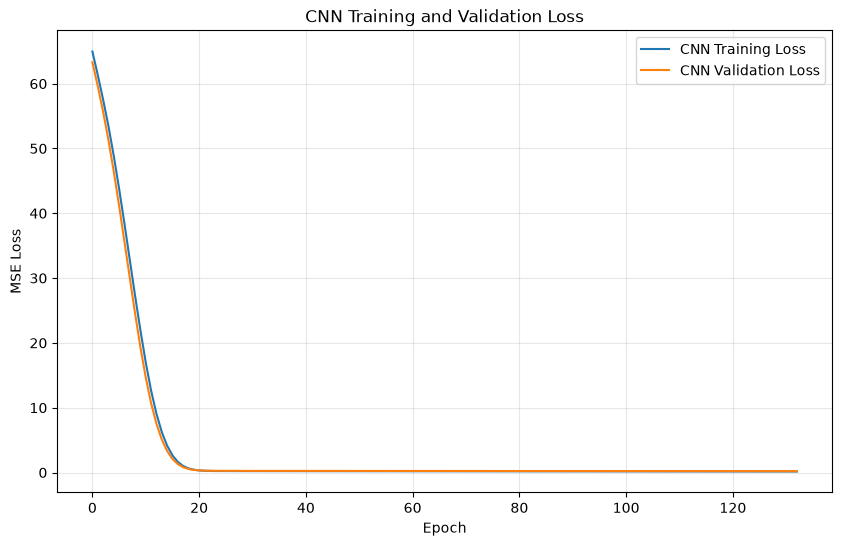

First training loss: 64.96342241441882
First validation loss: 63.30503845214844
Final training loss: 0.15660881976018082
Final validation loss: 0.20782656967639923
Best validation loss: 0.2064431607723236
Best epoch: 113
Epochs completed: 133


In [20]:
# cnn counting parameters
print("-----------------parameter count---------------------")
cnn_parameter_count = sum(
    parameter.numel()
    for parameter in cnn_model.parameters()
)

print("Number of CNN parameters:", cnn_parameter_count)

print("-----------------first plot record---------------------")

# first plot plus its data
cnn_learning_rate = 0.001
cnn_weight_decay = 0.0
cnn_batch_size = 32
cnn_max_epochs = 500
cnn_patience = 20

cnn_loss_function = nn.MSELoss()

cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=cnn_learning_rate,
    weight_decay=cnn_weight_decay
)
print("Architecture:", cnn_model)
print("Parameter count:", cnn_parameter_count)
print("Optimizer: Adam")
print("Learning rate:", cnn_learning_rate)
print("Batch size:", cnn_batch_size)
print("Weight decay:", cnn_weight_decay)
print("Maximum epochs:", cnn_max_epochs)
print("Stopping rule: stop after", cnn_patience,
      "epochs without validation improvement")

cnn_train_losses = []
cnn_val_losses = []

cnn_best_val_loss = float("inf")
cnn_best_model_state = None
cnn_best_epoch = 0
cnn_epochs_without_improvement = 0

import copy

for epoch in range(cnn_max_epochs):

    # Training
    cnn_model.train()
    total_train_loss = 0

    for sequence_batch, target_batch in cnn_train_loader:

        cnn_optimizer.zero_grad()

        predictions = cnn_model(sequence_batch)

        loss = cnn_loss_function(
            predictions,
            target_batch
        )

        loss.backward()
        cnn_optimizer.step()

        total_train_loss += (
            loss.item() * sequence_batch.size(0)
        )

    average_train_loss = (
        total_train_loss / len(cnn_train_dataset)
    )

    cnn_train_losses.append(average_train_loss)


    # Validation
    cnn_model.eval()

    with torch.no_grad():

        validation_predictions = cnn_model(
            cnn_val_tensors
        )

        validation_loss = cnn_loss_function(
            validation_predictions,
            val_target_tensor
        )

    cnn_val_losses.append(validation_loss.item())


    # Save the best validation checkpoint
    if validation_loss.item() < cnn_best_val_loss:

        cnn_best_val_loss = validation_loss.item()
        cnn_best_epoch = epoch + 1

        cnn_best_model_state = copy.deepcopy(
            cnn_model.state_dict()
        )

        cnn_epochs_without_improvement = 0

    else:
        cnn_epochs_without_improvement += 1


    # Early stopping
    if cnn_epochs_without_improvement >= cnn_patience:
        break

plt.figure(figsize=(10, 6))

plt.plot(
    cnn_train_losses,
    label="CNN Training Loss"
)

plt.plot(
    cnn_val_losses,
    label="CNN Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("First training loss:", cnn_train_losses[0])
print("First validation loss:", cnn_val_losses[0])

print("Final training loss:", cnn_train_losses[-1])
print("Final validation loss:", cnn_val_losses[-1])

print("Best validation loss:", cnn_best_val_loss)
print("Best epoch:", cnn_best_epoch)
print("Epochs completed:", len(cnn_train_losses))

In [21]:
# comparing different kernel size

class CharacterCNN(nn.Module):

    def __init__(self, vocab_size, kernel_size):
        super().__init__()

        self.convolution = nn.Conv1d(
            in_channels=vocab_size,
            out_channels=16,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.activation = nn.ReLU()

        self.pooling = nn.AdaptiveMaxPool1d(1)

        self.prediction = nn.Linear(16,1)

    def forward(self, x):

        x = self.convolution(x)
        x = self.activation(x)
        x = self.pooling(x)

        x = x.squeeze(-1)

        x = self.prediction(x)

        return x

# the function for training different kernel sizes

def train_cnn(kernel_size, seed=42):

    torch.manual_seed(seed)

    model = CharacterCNN(
        vocab_size=len(vocab),
        kernel_size=kernel_size
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=cnn_learning_rate,
        weight_decay=cnn_weight_decay
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        cnn_train_dataset,
        batch_size=cnn_batch_size,
        shuffle=True,
        generator=generator
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_model_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(cnn_max_epochs):

        model.train()
        total_train_loss = 0

        for sequence_batch, target_batch in train_loader:

            optimizer.zero_grad()

            predictions = model(sequence_batch)

            loss = cnn_loss_function(
                predictions,
                target_batch
            )

            loss.backward()
            optimizer.step()

            total_train_loss += (
                loss.item() * sequence_batch.size(0)
            )

        average_train_losses = total_train_loss / len(cnn_train_dataset)

        train_losses.append(average_train_losses)

        model.eval()

        with torch.no_grad():

             validation_predictions = model(cnn_val_tensors)

             validation_loss = cnn_loss_function(
                 validation_predictions,
                 val_target_tensor
                 )

        val_losses.append(validation_loss.item())

        if validation_loss.item() < best_val_loss:

            best_val_loss = validation_loss.item()
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_model_state)

    return (
        model,
        train_losses,
        val_losses,
        best_val_loss,
        best_epoch
    )



    
    





Config A: kernel size = 3
Parameter count: 1473
Best validation loss: 0.1836976557970047
Best epoch: 204
Epochs completed: 224

Config B: kernel size = 5
Parameter count: 2433
Best validation loss: 0.17149709165096283
Best epoch: 164
Epochs completed: 184
-------------------------------------plots------------------------------


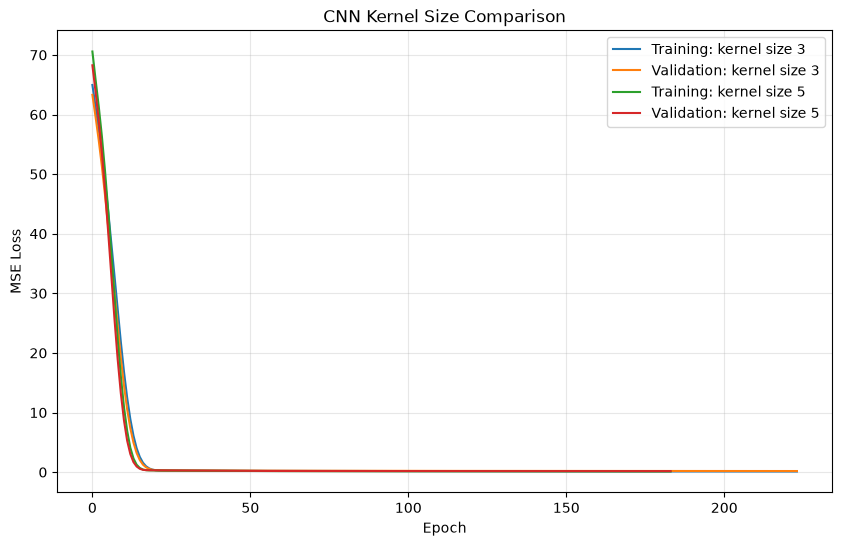

In [22]:
cnn_A, cnn_train_A, cnn_val_A, cnn_best_val_A, cnn_best_epoch_A = train_cnn(
    kernel_size=3,
    seed=42
)

cnn_B, cnn_train_B, cnn_val_B, cnn_best_val_B, cnn_best_epoch_B = train_cnn(
    kernel_size=5,
    seed=42
)

print("Config A: kernel size = 3")
print("Parameter count:", sum(
    parameter.numel()
    for parameter in cnn_A.parameters()
))
print("Best validation loss:", cnn_best_val_A)
print("Best epoch:", cnn_best_epoch_A)
print("Epochs completed:", len(cnn_train_A))

print()

print("Config B: kernel size = 5")
print("Parameter count:", sum(
    parameter.numel()
    for parameter in cnn_B.parameters()
))
print("Best validation loss:", cnn_best_val_B)
print("Best epoch:", cnn_best_epoch_B)
print("Epochs completed:", len(cnn_train_B))

print("-------------------------------------plots------------------------------")
plt.figure(figsize=(10, 6))

plt.plot(cnn_train_A, label="Training: kernel size 3")
plt.plot(cnn_val_A, label="Validation: kernel size 3")

plt.plot(cnn_train_B, label="Training: kernel size 5")
plt.plot(cnn_val_B, label="Validation: kernel size 5")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("CNN Kernel Size Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



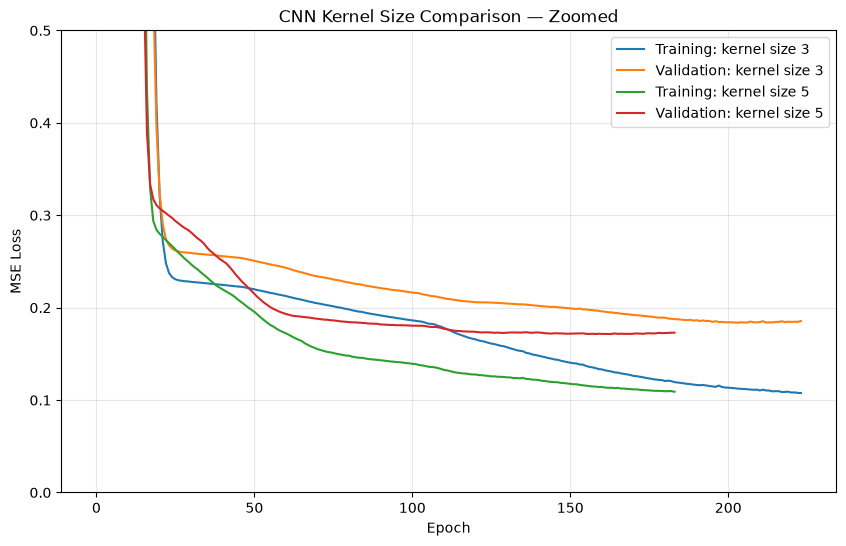

--------------------------------validation evidence------------------------
Selected CNN kernel size: 5
Selected validation loss: 0.17149709165096283
Selected checkpoint epoch: 164


In [23]:
plt.figure(figsize=(10, 6))

plt.plot(cnn_train_A, label="Training: kernel size 3")
plt.plot(cnn_val_A, label="Validation: kernel size 3")

plt.plot(cnn_train_B, label="Training: kernel size 5")
plt.plot(cnn_val_B, label="Validation: kernel size 5")

plt.ylim(0, 0.5)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("CNN Kernel Size Comparison — Zoomed")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("--------------------------------validation evidence------------------------")
selected_cnn = cnn_B

selected_cnn_kernel_size = 5
selected_cnn_best_val_loss = cnn_best_val_B
selected_cnn_best_epoch = cnn_best_epoch_B

print("Selected CNN kernel size:", selected_cnn_kernel_size)
print("Selected validation loss:", selected_cnn_best_val_loss)
print("Selected checkpoint epoch:", selected_cnn_best_epoch)


Both CNN configurations showed stable optimization because their training and validation losses decreased smoothly without large oscillations. However, the training losses continued to decrease after the validation losses began to level off, indicating mild overfitting. 

The kernel-size-3 model achieved a best validation MSE of 0.18370 at epoch 204. The kernel-size-5 model achieved a lower validation MSE of 0.17150 at epoch 164, an improvement of approxmately 6.6%. This supports the prediction that a wider kernel may detect useful patterns spanning more neighboring pSMILES characters.

However, the kernel-size-5 model also contained more parameters-2,433 compared with 1,473-so the improvement may result from both its wider local view and its greater model capacity. Early stopping selected the best validation checkpoint for each configuration and prevented further overfitting. 

##### Convolution kernel

A 1D convolution kernel examines neighboring chacters in the pSMILES sequence. The same kernel moves acorss the entire sequence, allowing it to detect a useful local pattern regardless of where that pattern occurs. For example, a kernel size of five examines five adjacent chacter positions at a time. During training, kernels can learn to respond to local combinations involving atom symbols, bonds, branches, and polymer connection symbols that are useful for predicting the HOMO-LUMO gap. 

Appuling the same approach to arbitrarily order of tabular properties is chosen by the dataset creator. Two properties appearing beside each other in a table are not necessarily more scientifically related than properties located farther apart. Reordering the columns would change the patterns seen by a convolution kernel even though the underlying information had not changed. Therefore, an MLP is more appropriate for these tabular features, while a CNN is appropriate for the ordered character sequence. 

# Part 5: Evaluate once and compare


------------------------CNN r2, mae, mse---------------------
Selected CNN test MSE: 0.21589912474155426
CNN test R²: 0.20646703243255615
CNN test MAE: 0.3022462725639343
CNN test MSE: 0.21589912474155426
CNN test RMSE: 0.46464946437239574
------------------------residual plots---------------------


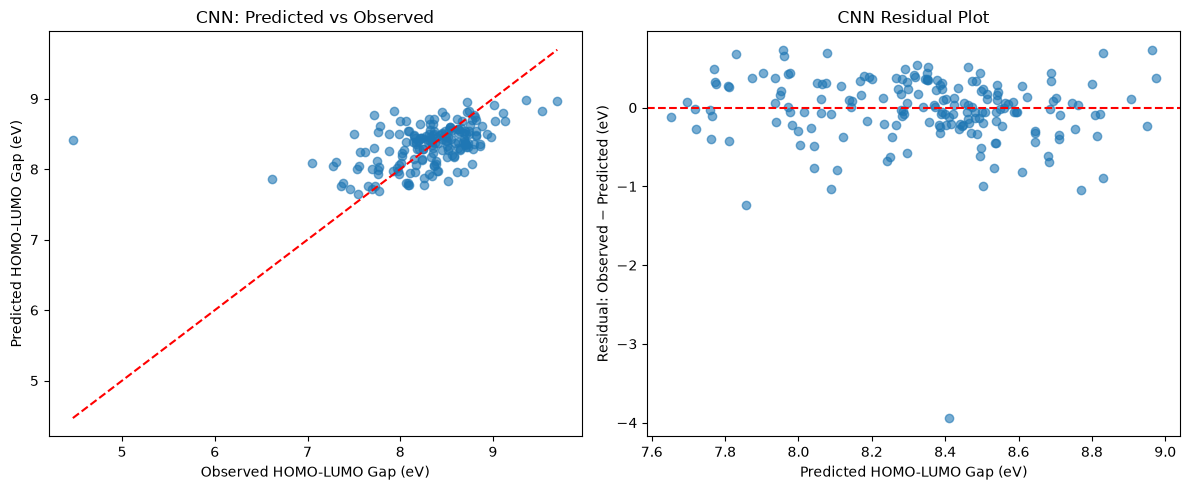

------------------------MLP r2, mae, mse---------------------
Selected MLP: weight decay = 0
Best validation MSE: 0.19604311883449554
Best checkpoint epoch: 202
MLP test R²: -0.016573071479797363
MLP test MAE: 0.36495456099510193
MLP test MSE: 0.27658236026763916
MLP test RMSE: 0.5259109813149362
------------------------residual plots---------------------


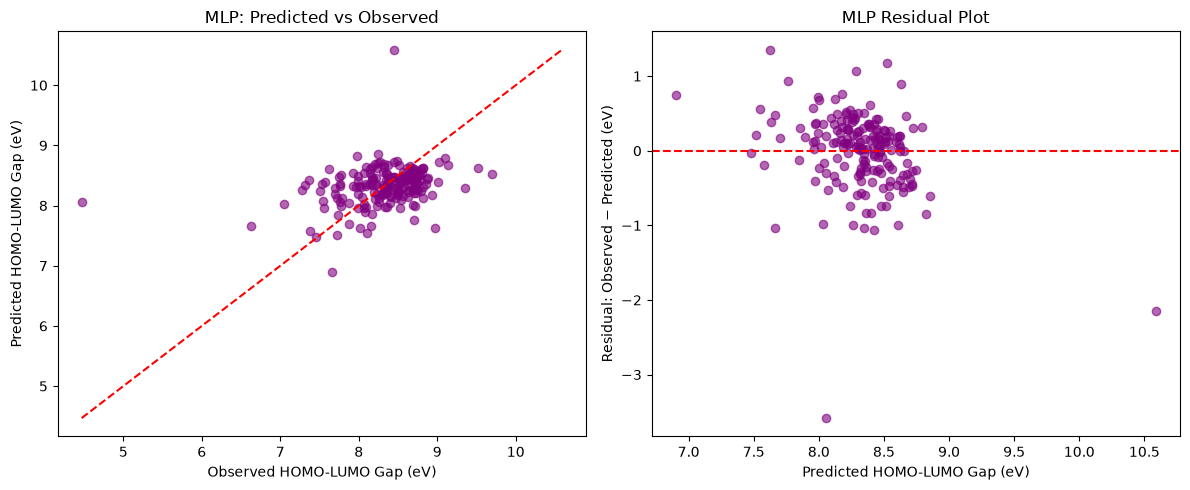

In [24]:
# test on test data
print("------------------------CNN r2, mae, mse---------------------")

selected_cnn.eval()

with torch.no_grad():

    cnn_test_predictions = selected_cnn(
        cnn_test_tensors
    )

    cnn_test_loss = cnn_loss_function(
        cnn_test_predictions,
        test_target_tensor
    )

print("Selected CNN test MSE:", cnn_test_loss.item())

# r2 mse mae

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

cnn_observed = test_target_tensor.squeeze().numpy()
cnn_predicted = cnn_test_predictions.squeeze().numpy()

cnn_test_r2 = r2_score(
    cnn_observed,
    cnn_predicted
)

cnn_test_mae = mean_absolute_error(
    cnn_observed,
    cnn_predicted
)

cnn_test_mse = mean_squared_error(
    cnn_observed,
    cnn_predicted
)

cnn_test_rmse = np.sqrt(cnn_test_mse)

print("CNN test R²:", cnn_test_r2)
print("CNN test MAE:", cnn_test_mae)
print("CNN test MSE:", cnn_test_mse)
print("CNN test RMSE:", cnn_test_rmse)

print("------------------------residual plots---------------------")
cnn_residuals = cnn_observed - cnn_predicted

plt.figure(figsize=(12, 5))

# Predicted versus observed
plt.subplot(1, 2, 1)

plt.scatter(
    cnn_observed,
    cnn_predicted,
    alpha=0.6
)

plot_min = min(cnn_observed.min(), cnn_predicted.min())
plot_max = max(cnn_observed.max(), cnn_predicted.max())

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    color="red"
)

plt.xlabel("Observed HOMO-LUMO Gap (eV)")
plt.ylabel("Predicted HOMO-LUMO Gap (eV)")
plt.title("CNN: Predicted vs Observed")


# Residual plot
plt.subplot(1, 2, 2)

plt.scatter(
    cnn_predicted,
    cnn_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--",
    color="red"
)

plt.xlabel("Predicted HOMO-LUMO Gap (eV)")
plt.ylabel("Residual: Observed − Predicted (eV)")
plt.title("CNN Residual Plot")

plt.tight_layout()
plt.show()

print("------------------------MLP r2, mae, mse---------------------")
selected_mlp = model_A

selected_mlp.eval()

with torch.no_grad():

    mlp_test_predictions_tensor = selected_mlp(
        test_predictors_tensors
    )

mlp_observed = test_target_tensor.squeeze().numpy()
mlp_predicted = mlp_test_predictions_tensor.squeeze().numpy()

mlp_test_r2 = r2_score(
    mlp_observed,
    mlp_predicted
)

mlp_test_mae = mean_absolute_error(
    mlp_observed,
    mlp_predicted
)

mlp_test_mse = mean_squared_error(
    mlp_observed,
    mlp_predicted
)

mlp_test_rmse = np.sqrt(mlp_test_mse)

print("Selected MLP: weight decay = 0")
print("Best validation MSE:", best_val_A)
print("Best checkpoint epoch:", best_epoch_A)

print("MLP test R²:", mlp_test_r2)
print("MLP test MAE:", mlp_test_mae)
print("MLP test MSE:", mlp_test_mse)
print("MLP test RMSE:", mlp_test_rmse)


print("------------------------residual plots---------------------")
mlp_residuals = mlp_observed - mlp_predicted

plt.figure(figsize=(12, 5))

# Predicted versus observed
plt.subplot(1, 2, 1)

plt.scatter(
    mlp_observed,
    mlp_predicted,
    alpha=0.6,
    color="purple"
)

plot_min = min(
    mlp_observed.min(),
    mlp_predicted.min()
)

plot_max = max(
    mlp_observed.max(),
    mlp_predicted.max()
)

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    color="red"
)

plt.xlabel("Observed HOMO-LUMO Gap (eV)")
plt.ylabel("Predicted HOMO-LUMO Gap (eV)")
plt.title("MLP: Predicted vs Observed")


# Residual plot
plt.subplot(1, 2, 2)

plt.scatter(
    mlp_predicted,
    mlp_residuals,
    alpha=0.6,
    color="purple"
)

plt.axhline(
    y=0,
    linestyle="--",
    color="red"
)

plt.xlabel("Predicted HOMO-LUMO Gap (eV)")
plt.ylabel("Residual: Observed − Predicted (eV)")
plt.title("MLP Residual Plot")

plt.tight_layout()
plt.show()


In [25]:
# getting the training time
mlp_start_time = time.perf_counter()

timed_mlp, _, _, timed_mlp_val, _ = train_model(
    weight_decay=0.0
)

mlp_training_time = time.perf_counter() - mlp_start_time


cnn_start_time = time.perf_counter()

timed_cnn, _, _, timed_cnn_val, _ = train_cnn(
    kernel_size=5,
    seed=42
)

cnn_training_time = time.perf_counter() - cnn_start_time


print("MLP training time:", mlp_training_time, "seconds")
print("CNN training time:", cnn_training_time, "seconds")

print("Repeated MLP validation MSE:", timed_mlp_val)
print("Repeated CNN validation MSE:", timed_cnn_val)

MLP training time: 0.7777029999997467 seconds
CNN training time: 10.680034583027009 seconds
Repeated MLP validation MSE: 0.19604311883449554
Repeated CNN validation MSE: 0.17149709165096283


In [26]:
# getting the baseline training time

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

baseline_train_predictors = cleaned_df.loc[
    train_idx
].drop(columns=["HOMO_LUMO_Gap_eV"])

baseline_test_predictors = cleaned_df.loc[
    test_idx
].drop(columns=["HOMO_LUMO_Gap_eV"])

baseline_train_target = cleaned_df.loc[
    train_idx,
    "HOMO_LUMO_Gap_eV"
]

baseline_test_target = cleaned_df.loc[
    test_idx,
    "HOMO_LUMO_Gap_eV"
]

baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

baseline_start_time = time.perf_counter()

baseline_model.fit(
    baseline_train_predictors,
    baseline_train_target
)

baseline_training_time = (
    time.perf_counter() - baseline_start_time
)

baseline_predictions = baseline_model.predict(
    baseline_test_predictors
)

baseline_test_r2 = r2_score(
    baseline_test_target,
    baseline_predictions
)

baseline_test_mae = mean_absolute_error(
    baseline_test_target,
    baseline_predictions
)

baseline_test_mse = mean_squared_error(
    baseline_test_target,
    baseline_predictions
)

baseline_test_rmse = np.sqrt(baseline_test_mse)

print("Baseline training time:", baseline_training_time)
print("Baseline test R²:", baseline_test_r2)
print("Baseline test MAE:", baseline_test_mae)
print("Baseline test MSE:", baseline_test_mse)
print("Baseline test RMSE:", baseline_test_rmse)

Baseline training time: 0.01155112503329292
Baseline test R²: 0.24935632725696255
Baseline test MAE: 0.3011451287691173
Baseline test MSE: 0.2042300995124566
Baseline test RMSE: 0.4519182442792685


# Comparison table

In [27]:
comparison_table = pd.DataFrame({
    "Model": [
        "Section 3 Linear Regression",
        "MLP",
        "1D CNN"
    ],

    "Input representation": [
        "10 numerical properties",
        "10 standardized numerical properties",
        "One-hot pSMILES: 30 channels × 98 positions"
    ],

    "Parameter count": [
        11,
        385,
        2433
    ],

    "Validation evidence": [
        "5-fold CV mean R² = 0.1644",
        "Best validation MSE = 0.1960",
        "Best validation MSE = 0.1715"
    ],

    "Test R²": [
        baseline_test_r2,
        mlp_test_r2,
        cnn_test_r2
    ],

    "Test MAE": [
        baseline_test_mae,
        mlp_test_mae,
        cnn_test_mae
    ],

    "Test MSE": [
        baseline_test_mse,
        mlp_test_mse,
        cnn_test_mse
    ],

    "Test RMSE": [
        baseline_test_rmse,
        mlp_test_rmse,
        cnn_test_rmse
    ],

    "Training time (seconds)": [
        baseline_training_time,
        mlp_training_time,
        cnn_training_time
    ],

    "Random seed": [
        42,
        42,
        42
    ]
})

comparison_table

,Model,Input representation,Parameter count,Validation evidence,Test R²,Test MAE,Test MSE,Test RMSE,Training time (seconds),Random seed
0,Section 3 Linear Regression,10 numerical properties,11,5-fold CV mean R² = 0.1644,0.249356,0.301145,0.204230,0.451918,0.011551,42
1,MLP,10 standardized numerical properties,385,Best validation MSE = 0.1960,-0.016573,0.364955,0.276582,0.525911,0.777703,42
2,1D CNN,One-hot pSMILES: 30 channels × 98 positions,2433,Best validation MSE = 0.1715,0.206467,0.302246,0.215899,0.464649,10.680035,42


## Part 5: Final Evaluation and Comparison

All model choices were fixed using training and validation evidence before final test evaluation. The selected MLP used no weight decay, while the selected CNN used a kernel size of five. The test set was not used to select either configuration.

### Test results

The Section 3 linear-regression baseline achieved the strongest overall test performance, with an R² of 0.2494, MAE of 0.3011 eV, MSE of 0.2042, and RMSE of 0.4519 eV.

The selected CNN achieved an R² of 0.2065, MAE of 0.3022 eV, MSE of 0.2159, and RMSE of 0.4646 eV. Its performance was close to the linear baseline but slightly worse on every test metric.

The selected MLP performed worst, with an R² of −0.0166, MAE of 0.3650 eV, MSE of 0.2766, and RMSE of 0.5259 eV. The negative R² means that the MLP performed slightly worse than predicting the test-set mean.

### Did either neural network meaningfully outperform the baseline?

Neither neural network outperformed the Section 3 linear-regression baseline. The CNN came close, but its R² was lower and its MAE, MSE, and RMSE were slightly higher. The MLP performed substantially worse. Therefore, the added complexity of the neural networks did not produce a practically meaningful improvement for this dataset.

The computational cost also increased. Linear regression trained in approximately 0.03 seconds, compared with 0.82 seconds for the MLP and 10.49 seconds for the CNN. The CNN therefore required considerably more training time without improving test performance.

### Evidence of overfitting or underfitting

The MLP and CNN training curves showed stable optimization because their losses decreased smoothly without large oscillations.

Both neural networks showed mild overfitting near the end of training. Their training losses continued decreasing after their validation losses had levelled off or begun increasing slightly. Early stopping limited this behavior and restored the checkpoint with the lowest validation loss.

The MLP’s weak test performance suggests poor generalization. Its predicted-versus-observed plot showed predictions concentrated around the central target range, along with several large errors. The CNN showed a similar tendency to predict values near the centre of the target distribution, although it generalized better than the MLP.

### What can be concluded from the MLP–CNN difference?

On this particular split, the CNN pipeline generalized better than the MLP pipeline. However, this does not prove that convolutional architecture is inherently better than an MLP.

The models used different representations. The MLP received ten calculated numerical properties, while the CNN received a character-level pSMILES sequence. Therefore, their performance difference reflects both the model architecture and the available input information. The comparison supports a conclusion about these complete pipelines, not an architecture-only conclusion.

### Most important threats to validity

The first major threat is the small dataset and reliance on one train-validation-test split. A few unusual molecules, particularly the low-gap test observation, have a noticeable effect on MSE, RMSE, and R². Results could change under a different split or across repeated seeds.

The second major threat is that the models did not receive equivalent representations or identical effective training sets. The MLP used calculated numerical properties, the CNN used pSMILES characters, and the Section 3 baseline used the full original training partition while the neural-network training partition reserved rows for validation. These differences make architecture-only comparisons impossible.

### Model carried into Section 5

Based on the current evidence, I would carry the linear-regression baseline into Section 5. It achieved the best test metrics, trained much faster, used far fewer parameters, and was easier to interpret.

The CNN would be the preferred neural-network candidate if Section 5 specifically required learning directly from pSMILES. It performed better than the MLP and demonstrated that the character sequence contained useful predictive information. However, its added complexity and training cost were not justified by improved test performance in this experiment.

# Part 6: Review the work

##### Suggestion accepted:
Change interpretation after rerunning the model and select the no-weight-decay MLP.

##### Evidence: 
After removing HOMO_eV and LUMO_eV, the saved outputs show validation MSEs of 0.196043 for no weight decay and 0.196157 for weight decay 0.0001. The old written values came from the leaked experiment and no longer match the notebook.

##### Suggestion changed or rejected:

Replace the one-hot character representation with a learned embedding.

I would reject this change for the current submission.

##### Evidence: 
The assignment explicitly accepts character channels with shape (batch, vocabulary_size, sequence_length). The saved tensors have the correct shape (592, 30, 98), and the CNN trains successfully. Introducing an embedding would create a new experiment after test evaluation and is unnecessary for satisfying the assignment.